# Single-Cell Transcriptomic Prioritization of Therapeutic Targets in Rheumatoid Arthritis

This project reanalyzes publicly available AMP RA Phase 1 single-cell RNA-seq data to characterize synovial cell states, identify disease-relevant transcriptional programs, and prioritize candidate therapeutic targets.

The workflow integrates:
- single-cell transcriptomic analysis with Scanpy
- differential expression analysis
- ranked gene set enrichment analysis (GSEA)
- leading-edge gene analysis
- cross-cell-state candidate integration
- transcriptomic evidence scoring
- sensitivity and sample-level robustness analyses

## 1. Setup

Import the Python libraries used throughout the analysis and define reproducible project paths.

In [1]:
import sys
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Single-cell analysis
import scanpy as sc
import anndata as ad

# Pathway enrichment
import gseapy as gp

# Reproducibility
np.random.seed(42)

print("Python:", sys.version.split()[0])
print("Scanpy:", version("scanpy"))
print("AnnData:", version("anndata"))
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("GSEApy:", gp.__version__)

Python: 3.12.15
Scanpy: 1.12.4
AnnData: 0.13.4
NumPy: 2.5.4
pandas: 3.0.6
GSEApy: 1.3.1


In [2]:
# Project directories
PROJECT_DIR = Path("..")

DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
FIGURES_DIR = PROJECT_DIR / "figures"

# Create output directories if they do not exist
RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)

print("Data directory:", DATA_DIR.resolve())
print("Results directory:", RESULTS_DIR.resolve())
print("Figures directory:", FIGURES_DIR.resolve())

Data directory: /Users/jacklyn/Documents/UCSF/Projects/single_cell_ra/data
Results directory: /Users/jacklyn/Documents/UCSF/Projects/single_cell_ra/results
Figures directory: /Users/jacklyn/Documents/UCSF/Projects/single_cell_ra/figures


## 2. Load Data

Load the processed AMP RA Phase 1 single-cell expression matrix and published cell-level metadata.

The expression matrix was previously quality controlled and transformed to log2(CPM + 1) by the original study. Therefore, raw-count normalization and cell-level QC filtering are not repeated in this reanalysis.

In [3]:
# Input files
EXPR_FILE = DATA_DIR / "exprMatrix.tsv"
META_FILE = DATA_DIR / "meta"

print("Expression matrix exists:", EXPR_FILE.exists())
print("Metadata exists:", META_FILE.exists())

Expression matrix exists: True
Metadata exists: True


In [4]:
# Load expression matrix and cell metadata
expr = pd.read_csv(EXPR_FILE, sep="\t")
meta = pd.read_csv(META_FILE, sep="\t")

print("Expression matrix shape:", expr.shape)
print("Metadata shape:", meta.shape)

display(expr.iloc[:5, :6])
display(meta.head())

Expression matrix shape: (29165, 5266)
Metadata shape: (12123, 2)


,gene,S006_L1Q1_A03,S006_L1Q1_A05,S006_L1Q1_A07,S006_L1Q1_A09,S006_L1Q1_A11
0,A1BG,0.0,0.000000,0.0,0.0,0.0
1,A1BG-AS1,0.0,0.000000,0.0,0.0,0.0
2,A1CF,0.0,0.000000,0.0,0.0,0.0
3,A2M,0.0,0.000000,0.0,0.0,0.0
4,A2M-AS1,0.0,7.628549,0.0,0.0,0.0


,NAME,Cluster
0,TYPE,group
1,S006_L1Q1_A03,SC-T1
2,S006_L1Q1_A05,SC-T4
3,S006_L1Q1_A07,SC-T1
4,S006_L1Q1_A09,SC-T1


## 3. Prepare Expression Matrix and Metadata

The downloaded expression matrix is organized as genes × cells, whereas AnnData expects observations (cells) × variables (genes).

Cell metadata are filtered to retain only cells present in the expression matrix. Sample identifiers are extracted from the cell names for downstream sample-level robustness analyses.

In [5]:
# Move gene names to the index and transpose to cells × genes
expr_t = (
    expr
    .set_index("gene")
    .T
)

print("Expression matrix after transpose:", expr_t.shape)
print("Cells:", expr_t.shape[0])
print("Genes:", expr_t.shape[1])

display(expr_t.iloc[:5, :5])

Expression matrix after transpose: (5265, 29165)
Cells: 5265
Genes: 29165


gene,A1BG,A1BG-AS1,A1CF,A2M,A2M-AS1
S006_L1Q1_A03,0.0,0.0,0.0,0.0,0.000000
S006_L1Q1_A05,0.0,0.0,0.0,0.0,7.628549
S006_L1Q1_A07,0.0,0.0,0.0,0.0,0.000000
S006_L1Q1_A09,0.0,0.0,0.0,0.0,0.000000
S006_L1Q1_A11,0.0,0.0,0.0,0.0,0.000000


In [6]:
# Remove the metadata header row embedded in the file
meta_clean = meta[
    meta["NAME"] != "TYPE"
].copy()

# Keep only cells present in the expression matrix
ra_meta = meta_clean[
    meta_clean["NAME"].isin(expr_t.index)
].copy()

# Extract sample ID from cell names
# Example: S006_L1Q1_A03 -> S006
ra_meta["Sample"] = (
    ra_meta["NAME"]
    .str.split("_")
    .str[0]
)

print("Filtered metadata shape:", ra_meta.shape)
print("Unique samples:", ra_meta["Sample"].nunique())
print("Unique clusters:", ra_meta["Cluster"].nunique())

display(ra_meta.head())

Filtered metadata shape: (5265, 3)
Unique samples: 24
Unique clusters: 18


,NAME,Cluster,Sample
1,S006_L1Q1_A03,SC-T1,S006
2,S006_L1Q1_A05,SC-T4,S006
3,S006_L1Q1_A07,SC-T1,S006
4,S006_L1Q1_A09,SC-T1,S006
5,S006_L1Q1_A11,SC-T4,S006


In [7]:
# Set cell IDs as the metadata index
ra_meta = ra_meta.set_index("NAME")

# Reorder metadata to exactly match the expression matrix
ra_meta = ra_meta.loc[expr_t.index]

# Verify alignment
assert expr_t.index.equals(ra_meta.index), \
    "Cell IDs between expression matrix and metadata do not match."

print("Cell ID alignment: PASSED")
print("Expression cells:", expr_t.shape[0])
print("Metadata cells:", ra_meta.shape[0])

display(ra_meta.head())

Cell ID alignment: PASSED
Expression cells: 5265
Metadata cells: 5265


,Cluster,Sample
S006_L1Q1_A03,SC-T1,S006
S006_L1Q1_A05,SC-T4,S006
S006_L1Q1_A07,SC-T1,S006
S006_L1Q1_A09,SC-T1,S006
S006_L1Q1_A11,SC-T4,S006


## 4. Construct AnnData

The aligned expression matrix and cell metadata are combined into an AnnData object, the primary data structure used by Scanpy.

Rows represent individual cells and columns represent genes.

In [8]:
# Construct AnnData object
adata = ad.AnnData(
    X=expr_t,
    obs=ra_meta.copy()
)

# Ensure informative index names
adata.obs_names.name = "Cell"
adata.var_names.name = "Gene"

print(adata)
print("\nShape:", adata.shape)

display(adata.obs.head())

AnnData object with n_obs × n_vars = 5265 × 29165
    obs: 'Cluster', 'Sample'
    layers: None (.X)

Shape: (5265, 29165)


,Cluster,Sample
Cell,,
S006_L1Q1_A03,SC-T1,S006
S006_L1Q1_A05,SC-T4,S006
S006_L1Q1_A07,SC-T1,S006
S006_L1Q1_A09,SC-T1,S006
S006_L1Q1_A11,SC-T4,S006


In [9]:
# Basic integrity checks
assert adata.n_obs == 5265
assert adata.n_vars == 29165
assert adata.obs_names.is_unique
assert adata.var_names.is_unique
assert adata.obs["Cluster"].nunique() == 18
assert adata.obs["Sample"].nunique() == 24

print("AnnData integrity checks: PASSED")
print(f"Cells: {adata.n_obs:,}")
print(f"Genes: {adata.n_vars:,}")
print(f"Cell states: {adata.obs['Cluster'].nunique()}")
print(f"Samples: {adata.obs['Sample'].nunique()}")

AnnData integrity checks: PASSED
Cells: 5,265
Genes: 29,165
Cell states: 18
Samples: 24


## 5. Highly Variable Gene Selection

Highly variable genes (HVGs) capture genes with informative variation across cells and reduce the influence of less informative features during dimensionality reduction.

Because the downloaded expression matrix was already transformed to log2(CPM + 1) by the original study, normalization and log transformation are not repeated. The Seurat-style HVG method is applied to select 2,000 informative genes.

In [10]:
# Preserve the processed log2(CPM + 1) expression matrix
adata.layers["log2cpm"] = adata.X.copy()

# Identify highly variable genes
sc.pp.highly_variable_genes(
    adata,
    flavor="seurat",
    n_top_genes=2000
)

n_hvg = int(adata.var["highly_variable"].sum())

print(f"Highly variable genes selected: {n_hvg:,}")

assert n_hvg == 2000

Highly variable genes selected: 2,000


In [11]:
hvg_summary = (
    adata.var
    .loc[adata.var["highly_variable"]]
    .sort_values(
        "dispersions_norm",
        ascending=False
    )
)

display(hvg_summary.head(10))

,highly_variable,means,dispersions,dispersions_norm
Gene,,,,
IGLV3-25,True,6.076263,14.520686,11.326476
IGKV3-11,True,6.032635,14.479891,11.251310
CCL21,True,5.393657,13.942512,10.261168
IGLV4-60,True,5.371489,13.917759,10.208692
IGKV1-16,True,5.331365,13.813364,10.020452
IGKV1D-12,True,6.698414,14.735245,9.905657
RP11-325I22.2,True,5.042111,13.595527,9.627664
IGLV3-10,True,6.177415,14.403937,9.369062
IGKV1-27,True,6.576962,14.195822,9.031994


## 6. PCA and Neighborhood Graph

Principal component analysis (PCA) reduces the 2,000 highly variable genes into a lower-dimensional representation of transcriptional variation.

A nearest-neighbor graph is then constructed in PCA space and used as the basis for UMAP visualization.

In [12]:
# Principal component analysis using highly variable genes
sc.tl.pca(
    adata,
    n_comps=50,
    mask_var="highly_variable"
)

print("PCA coordinates:", adata.obsm["X_pca"].shape)

assert adata.obsm["X_pca"].shape == (5265, 50)

PCA coordinates: (5265, 50)


In [13]:
# Construct nearest-neighbor graph in PCA space
sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=30
)

print("Neighbor graph constructed.")
print("Distances:", adata.obsp["distances"].shape)
print("Connectivities:", adata.obsp["connectivities"].shape)

/Users/jacklyn/miniforge3/envs/single-cell-ra/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Neighbor graph constructed.
Distances: (5265, 5265)
Connectivities: (5265, 5265)


## 7. UMAP Visualization of Synovial Cell States

UMAP was computed from the PCA-based nearest-neighbor graph to visualize transcriptional relationships among the 5,265 cells.

Published cluster annotations are overlaid after dimensionality reduction and were not used to construct the UMAP embedding.

In [14]:
# Compute UMAP embedding
sc.tl.umap(
    adata,
    random_state=42
)

print("UMAP embedding computed.")

UMAP embedding computed.


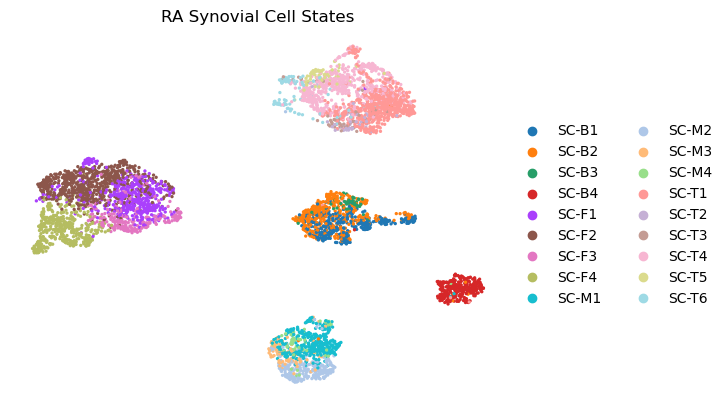

In [15]:
sc.pl.umap(
    adata,
    color="Cluster",
    title="RA Synovial Cell States",
    frameon=False,
    legend_loc="right margin",
    show=False
)

plt.savefig(
    FIGURES_DIR / "01_umap_cell_states.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

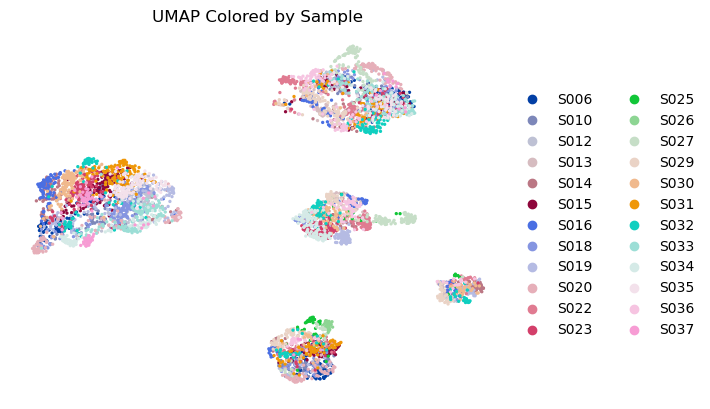

In [16]:
sc.pl.umap(
    adata,
    color="Sample",
    title="UMAP Colored by Sample",
    frameon=False,
    legend_loc="right margin",
    show=False
)

plt.savefig(
    FIGURES_DIR / "02_umap_by_sample.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 8. Canonical Marker Expression

Expression of representative marker genes was projected onto the UMAP embedding to evaluate the biological organization of the reconstructed cell-state landscape.

Selected markers represent antigen-presentation, inflammatory myeloid, T-cell, and autoimmune-associated B-cell programs.

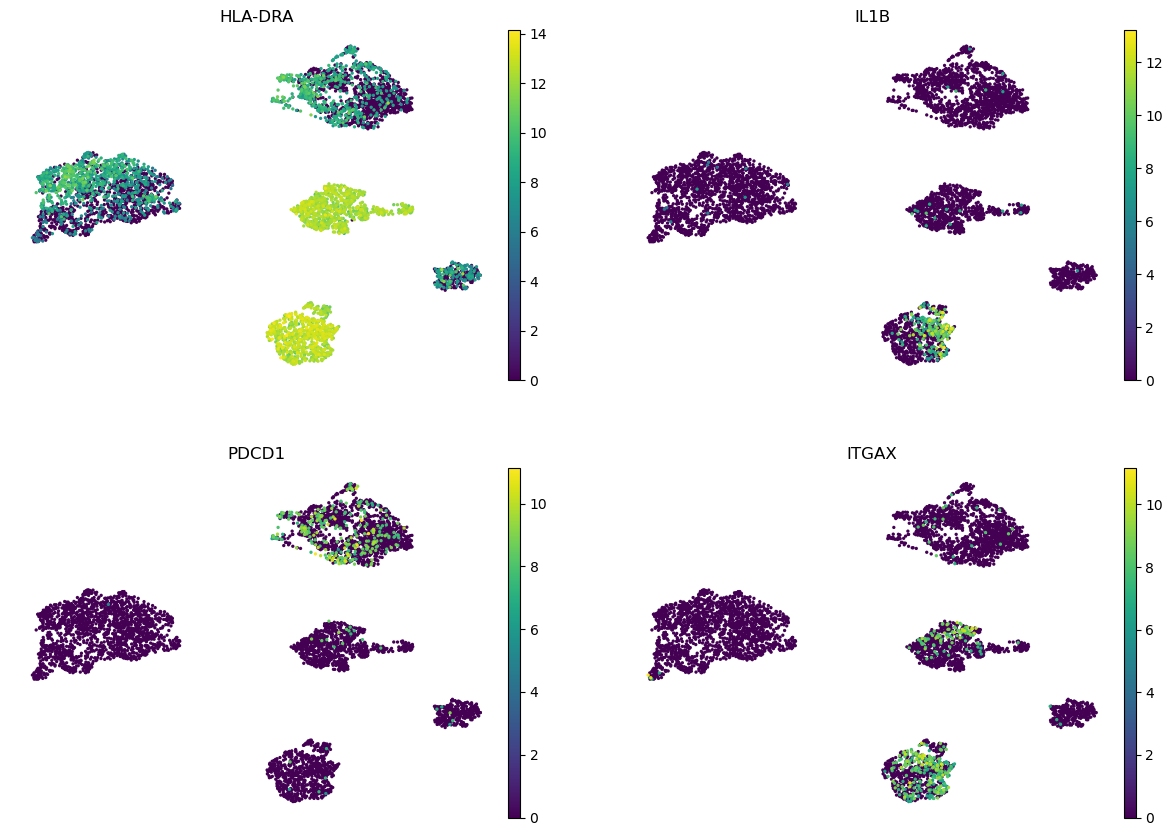

In [17]:
marker_genes = [
    "HLA-DRA",
    "IL1B",
    "PDCD1",
    "ITGAX"
]

sc.pl.umap(
    adata,
    color=marker_genes,
    ncols=2,
    frameon=False,
    show=False
)

plt.savefig(
    FIGURES_DIR / "03_umap_marker_expression.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 9. Differential Expression and Cell-State Markers

Cluster-associated genes were identified using the Wilcoxon rank-sum method implemented in Scanpy.

Each published cell state was compared with the remaining cells to identify genes preferentially expressed within that state. These results provide the ranked gene statistics used for downstream pathway enrichment analysis.

In [18]:
sc.tl.rank_genes_groups(
    adata,
    groupby="Cluster",
    method="wilcoxon",
    use_raw=False
)

print("Differential expression analysis completed.")

Differential expression analysis completed.


In [19]:
markers = sc.get.rank_genes_groups_df(
    adata,
    group=None
)

print("Marker results:", markers.shape)

display(
    markers[
        [
            "group",
            "names",
            "scores",
            "logfoldchanges",
            "pvals_adj"
        ]
    ].head(10)
)

Marker results: (524970, 6)


,group,names,scores,logfoldchanges,pvals_adj
0,SC-B1,CD83,28.630514,11.999625,8.174791e-176
1,SC-B1,MS4A1,27.309961,13.386632,4.710639e-160
2,SC-B1,CD37,27.154974,8.944002,2.150220e-158
3,SC-B1,BANK1,26.104443,11.206630,2.366785e-146
4,SC-B1,CD79A,25.514194,11.986408,8.001280e-140
5,SC-B1,LY9,25.314569,10.826208,1.073237e-137
6,SC-B1,CD69,23.554272,10.019810,4.137700e-119
7,SC-B1,CXCR4,23.446722,8.776365,4.626514e-118
8,SC-B1,RALGPS2,23.368895,9.431944,2.583034e-117
9,SC-B1,HLA-DQA1,23.199425,9.488861,1.223455e-115


## 10. Ranked Gene Set Enrichment Analysis

Ranked gene set enrichment analysis (GSEA) was used to identify biological programs associated with selected disease-relevant cell states.

For each cell state, all genes were ranked using the Wilcoxon differential-expression score rather than applying an arbitrary significance or fold-change cutoff. The ranked gene lists were tested against Gene Ontology Biological Process gene sets using GSEApy.

Five cell states highlighted in the original study were evaluated:

- **SC-F2** — HLA-DRA-high sublining fibroblasts
- **SC-M1** — IL1B-positive pro-inflammatory monocytes
- **SC-M4** — interferon-activated monocytes
- **SC-T3** — PDCD1-positive T peripheral helper / T follicular helper cells
- **SC-B3** — autoimmune-associated B cells

Positive enrichment with FDR < 0.05 was considered significant.

In [20]:
disease_clusters = [
    "SC-F2",
    "SC-M1",
    "SC-M4",
    "SC-T3",
    "SC-B3"
]

print("Cell states selected for ranked GSEA:")
for cluster in disease_clusters:
    print("-", cluster)

Cell states selected for ranked GSEA:
- SC-F2
- SC-M1
- SC-M4
- SC-T3
- SC-B3


In [21]:
gsea_results = {}

for cluster in disease_clusters:

    # Rank all genes by cluster-specific Wilcoxon score
    rank_df = (
        markers.loc[
            markers["group"] == cluster,
            ["names", "scores"]
        ]
        .dropna()
        .sort_values(
            "scores",
            ascending=False
        )
    )

    # Ranked GSEA
    gsea = gp.prerank(
        rnk=rank_df,
        gene_sets="GO_Biological_Process_2025",
        min_size=15,
        max_size=500,
        permutation_num=1000,
        seed=42,
        outdir=None,
        verbose=False
    )

    gsea_results[cluster] = gsea.res2d.copy()

    print(f"{cluster}: completed")

2026-10-27 10:56:19,583 [WARNING] Duplicated values found in preranked stats: 39.57% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-10-27 10:56:50,375 [WARNING] Duplicated values found in preranked stats: 46.08% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


SC-F2: completed


2026-10-27 10:57:22,870 [WARNING] Duplicated values found in preranked stats: 57.27% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


SC-M1: completed


2026-10-27 10:57:54,042 [WARNING] Duplicated values found in preranked stats: 58.33% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


SC-M4: completed


2026-10-27 10:58:25,143 [WARNING] Duplicated values found in preranked stats: 58.07% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


SC-T3: completed
SC-B3: completed


In [22]:
gsea_summary_list = []

for cluster in disease_clusters:

    result = gsea_results[cluster].copy()

    significant = result[
        (result["NES"] > 0) &
        (result["FDR q-val"] < 0.05)
    ].copy()

    significant["Cluster"] = cluster

    gsea_summary_list.append(significant)

gsea_summary = pd.concat(
    gsea_summary_list,
    ignore_index=True
)

print(
    "Significant positively enriched pathways:",
    len(gsea_summary)
)

display(
    gsea_summary[
        [
            "Cluster",
            "Term",
            "NES",
            "FDR q-val",
            "Lead_genes"
        ]
    ].head(15)
)

Significant positively enriched pathways: 132


,Cluster,Term,NES,FDR q-val,Lead_genes
0,SC-F2,Collagen Fibril Organization (GO:0030199),1.540842,0.007743,COL3A1;COL1A1;COL1A2;COL14A1;SERPINH1;COL5A2;D...
1,SC-M1,Positive Regulation of Chemokine Production (G...,2.050815,0.000000,AIF1;CD74;CSF1R;CLEC7A;HMOX1;HIF1A;SYK;TLR2;LG...
2,SC-M1,Antigen Processing and Presentation of Exogeno...,1.999580,0.000000,HLA-DPA1;HLA-DRB1;CTSS;IFI30;HLA-DRA;FCER1G;HL...
3,SC-M1,Positive Regulation of Immune Response (GO:005...,1.945179,0.003594,HLA-DPA1;HLA-DRB1;HLA-DRA;CD74;HLA-DQA1;HLA-DM...
4,SC-M1,Positive Regulation of Interleukin-6 Productio...,1.933668,0.003594,TYROBP;AIF1;CD74;CLEC7A;LILRB2;SYK;TLR2;LGALS9...
5,SC-M1,Regulation of Chemokine Production (GO:0032642),1.933491,0.002875,AIF1;CD74;CSF1R;LILRB4;HMOX1;HIF1A;TLR2;LGALS9...
6,SC-M1,Positive Regulation of Immune System Process (...,1.931137,0.002396,HLA-DPA1;HLA-DRB1;HLA-DRA;HLA-DQA1;HLA-DMA;HLA...
7,SC-M1,Regulation of Interleukin-6 Production (GO:003...,1.922125,0.002053,TYROBP;AIF1;CD74;CLEC7A;LILRB2;LILRB4;SYK;TLR2...
8,SC-M1,Regulation of Interleukin-1 Beta Production (G...,1.915608,0.002246,TYROBP;CCL3;CLEC7A;LILRB4;LGALS9;PYCARD;TLR4;E...
9,SC-M1,Antigen Processing and Presentation of Exogeno...,1.913152,0.001797,HLA-DPA1;HLA-DRB1;CTSS;IFI30;HLA-DRA;FCER1G;HL...


## 11. Leading-Edge Candidate Identification

Genes contributing to the leading edge of significant GSEA pathways were extracted as candidate genes.

For each cell state, pathway recurrence was quantified as the number of significant enriched pathways in which a gene appeared as a leading-edge contributor. This provides pathway-level evidence complementary to differential-expression strength.

In [23]:
all_candidates = []

for cluster in disease_clusters:

    # Significant pathways for this cell state
    sig = gsea_summary[
        gsea_summary["Cluster"] == cluster
    ].copy()

    # Expand semicolon-separated leading-edge genes
    leading_genes = (
        sig["Lead_genes"]
        .str.split(";")
        .explode()
        .dropna()
    )

    # Count pathway recurrence for each gene
    candidates = (
        leading_genes
        .value_counts()
        .rename_axis("Gene")
        .reset_index(name="Pathway_Count")
    )

    candidates["Cluster"] = cluster

    # Differential-expression evidence
    de = (
        markers.loc[
            markers["group"] == cluster,
            ["names", "scores", "logfoldchanges", "pvals_adj"]
        ]
        .rename(columns={"names": "Gene"})
    )

    # Combine pathway and differential-expression evidence
    candidates = candidates.merge(
        de,
        on="Gene",
        how="left"
    )

    all_candidates.append(candidates)

candidate_table = pd.concat(
    all_candidates,
    ignore_index=True
)

print(
    "Candidate cluster-gene pairs:",
    len(candidate_table)
)

display(candidate_table.head(10))

Candidate cluster-gene pairs: 1018


,Gene,Pathway_Count,Cluster,scores,logfoldchanges,pvals_adj
0,COL3A1,1,SC-F2,36.958992,11.241360,1.904120e-295
1,COL1A1,1,SC-F2,36.853718,11.378481,8.262649e-294
2,COL1A2,1,SC-F2,36.094391,10.839923,5.062891e-282
3,COL14A1,1,SC-F2,35.793316,11.536611,2.273451e-277
4,SERPINH1,1,SC-F2,35.683132,9.542183,1.108412e-275
5,COL5A2,1,SC-F2,34.838531,10.358058,7.409061e-263
6,DPT,1,SC-F2,34.125107,10.822119,2.684871e-252
7,CYP1B1,1,SC-F2,33.673347,10.605618,1.150294e-245
8,LUM,1,SC-F2,33.353371,11.059176,4.520351e-241
9,COL5A1,1,SC-F2,32.945927,9.418917,3.135827e-235


In [24]:
gene_summary = (
    candidate_table
    .groupby("Gene")
    .agg(
        Cross_Cluster_Count=("Cluster", "nunique"),
        Total_Pathway_Count=("Pathway_Count", "sum"),
        Max_Pathway_Count=("Pathway_Count", "max"),
        Max_logFC=("logfoldchanges", "max"),
        Max_DE_Score=("scores", "max"),
        Min_FDR=("pvals_adj", "min"),
        Clusters=(
            "Cluster",
            lambda x: ";".join(sorted(set(x)))
        )
    )
    .reset_index()
)

print(
    "Unique candidate genes:",
    len(gene_summary)
)

display(
    gene_summary
    .sort_values(
        "Total_Pathway_Count",
        ascending=False
    )
    .head(15)
)

Unique candidate genes: 673


,Gene,Cross_Cluster_Count,Total_Pathway_Count,Max_Pathway_Count,Max_logFC,Max_DE_Score,Min_FDR,Clusters
477,PYCARD,3,47,27,4.480454,12.462038,1.303833e-33,SC-B3;SC-M1;SC-M4
261,HLA-DRB1,3,43,20,9.411464,27.164026,1.008588e-158,SC-B3;SC-M1;SC-M4
631,TLR4,2,42,26,4.600890,10.822420,2.015857e-25,SC-M1;SC-M4
329,LGALS9,3,41,22,6.219076,13.267825,4.503649e-38,SC-B3;SC-M1;SC-M4
203,FCGR2B,3,38,18,7.537895,18.437599,2.224308e-73,SC-B3;SC-M1;SC-M4
129,CLEC7A,2,33,17,8.594335,18.744936,7.573256e-76,SC-M1;SC-M4
615,SYK,3,32,16,8.235717,15.176057,9.172608e-50,SC-B3;SC-M1;SC-M4
336,LILRB1,3,32,18,4.640917,5.439537,8.583892e-07,SC-B3;SC-M1;SC-M4
338,LILRB4,2,31,19,8.765031,16.923351,8.408118e-62,SC-M1;SC-M4
659,TYROBP,2,30,16,14.064019,28.094490,3.336146e-169,SC-M1;SC-M4


## 12. Transcriptomic Candidate Prioritization

Candidate genes were prioritized by integrating complementary evidence from the single-cell analysis:

- **Pathway recurrence** — frequency across significant GSEA leading edges
- **Cross-cell-state recurrence** — number of analyzed cell states supporting the candidate
- **Expression effect size** — maximum log fold change
- **Differential-expression strength** — maximum Wilcoxon score
- **Statistical evidence** — minimum FDR-adjusted p-value

Each feature was min-max scaled to the range 0–1 before integration. An equal-weight composite score was used as an exploratory **Transcriptomic Evidence Score**.

This score reflects convergence of transcriptomic and pathway evidence and should not be interpreted as predicted therapeutic efficacy.

In [25]:
target_table = gene_summary.copy()


def minmax(series):
    """Scale a numeric pandas Series to the range 0–1."""
    value_range = series.max() - series.min()

    if value_range == 0:
        return pd.Series(
            0.0,
            index=series.index
        )

    return (
        (series - series.min()) /
        value_range
    )


# Normalize transcriptomic evidence features
target_table["Pathway_Score"] = minmax(
    target_table["Total_Pathway_Count"]
)

target_table["CrossCluster_Score"] = minmax(
    target_table["Cross_Cluster_Count"]
)

target_table["Expression_Score"] = minmax(
    target_table["Max_logFC"]
)

target_table["DE_Score"] = minmax(
    target_table["Max_DE_Score"]
)

# Convert smaller FDR values into larger evidence values
target_table["FDR_Evidence"] = -np.log10(
    target_table["Min_FDR"].clip(lower=1e-300)
)

target_table["FDR_Score"] = minmax(
    target_table["FDR_Evidence"]
)

In [26]:
evidence_features = [
    "Pathway_Score",
    "CrossCluster_Score",
    "Expression_Score",
    "DE_Score",
    "FDR_Score"
]

target_table["Transcriptomic_Evidence_Score"] = (
    target_table[evidence_features]
    .mean(axis=1)
)

target_table = target_table.sort_values(
    "Transcriptomic_Evidence_Score",
    ascending=False
).reset_index(drop=True)

display(
    target_table[
        [
            "Gene",
            "Transcriptomic_Evidence_Score",
            "Cross_Cluster_Count",
            "Total_Pathway_Count",
            "Max_logFC",
            "Max_DE_Score",
            "Min_FDR",
            "Clusters"
        ]
    ].head(20)
)

,Gene,Transcriptomic_Evidence_Score,Cross_Cluster_Count,Total_Pathway_Count,Max_logFC,Max_DE_Score,Min_FDR,Clusters
0,HLA-DRB1,0.709645,3,43,9.411464,27.164026,1.008588e-158,SC-B3;SC-M1;SC-M4
1,HLA-DPA1,0.637925,3,27,8.754436,27.379230,7.069214e-161,SC-B3;SC-M1;SC-M4
2,HLA-DRA,0.627016,3,28,9.554491,25.748013,7.068232e-143,SC-B3;SC-M1;SC-M4
3,TYROBP,0.599195,2,30,14.064019,28.094490,3.336146e-169,SC-M1;SC-M4
4,FCGR2B,0.568884,3,38,7.537895,18.437599,2.224308e-73,SC-B3;SC-M1;SC-M4
5,HLA-DQA1,0.556835,3,22,9.305830,22.352938,8.911552e-108,SC-B3;SC-M1;SC-M4
6,IFI30,0.551012,3,7,11.064301,26.084103,1.610844e-146,SC-B3;SC-M1;SC-M4
7,CTSS,0.545891,3,10,8.501899,26.124975,6.148362e-147,SC-B3;SC-M1;SC-M4
8,CD74,0.531936,3,13,6.046791,25.413525,3.258335e-139,SC-B3;SC-M1;SC-M4
9,HLA-DMB,0.529363,3,24,8.440372,19.778227,2.089525e-84,SC-B3;SC-M1;SC-M4


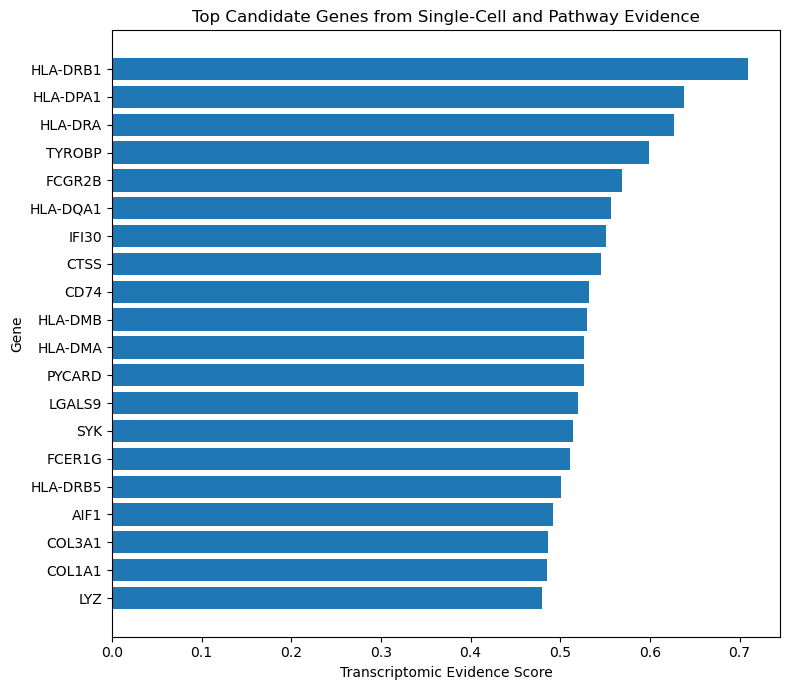

In [27]:
top20 = target_table.head(20).sort_values(
    "Transcriptomic_Evidence_Score",
    ascending=True
)

plt.figure(figsize=(8, 7))

plt.barh(
    top20["Gene"],
    top20["Transcriptomic_Evidence_Score"]
)

plt.xlabel("Transcriptomic Evidence Score")
plt.ylabel("Gene")
plt.title(
    "Top Candidate Genes from Single-Cell and Pathway Evidence"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "04_transcriptomic_candidate_ranking.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 13. Robustness of Candidate Ranking

Because the Transcriptomic Evidence Score combines multiple evidence types, sensitivity analyses were performed to determine whether the highest-ranked candidates depended strongly on the selected weighting scheme.

Two complementary tests were performed:

1. **Alternative weighting schemes** — rankings were recalculated using equal, biology-focused, and statistics-focused weights.
2. **Leave-one-feature-out analysis** — rankings were recalculated after removing each evidence component individually.

Candidates consistently retained among the top 20 were considered robust to scoring assumptions.

In [28]:
# Equal weighting
target_table["Score_equal"] = (
    0.20 * target_table["Pathway_Score"] +
    0.20 * target_table["CrossCluster_Score"] +
    0.20 * target_table["Expression_Score"] +
    0.20 * target_table["DE_Score"] +
    0.20 * target_table["FDR_Score"]
)

# Greater emphasis on pathway and cross-cell-state evidence
target_table["Score_biology"] = (
    0.30 * target_table["Pathway_Score"] +
    0.25 * target_table["CrossCluster_Score"] +
    0.25 * target_table["Expression_Score"] +
    0.10 * target_table["DE_Score"] +
    0.10 * target_table["FDR_Score"]
)

# Greater emphasis on differential-expression evidence
target_table["Score_statistics"] = (
    0.15 * target_table["Pathway_Score"] +
    0.10 * target_table["CrossCluster_Score"] +
    0.25 * target_table["Expression_Score"] +
    0.25 * target_table["DE_Score"] +
    0.25 * target_table["FDR_Score"]
)

top_equal = set(
    target_table.nlargest(20, "Score_equal")["Gene"]
)

top_biology = set(
    target_table.nlargest(20, "Score_biology")["Gene"]
)

top_statistics = set(
    target_table.nlargest(20, "Score_statistics")["Gene"]
)

stable_targets = (
    top_equal &
    top_biology &
    top_statistics
)

print(
    "Stable top-20 genes across all weighting schemes:",
    len(stable_targets)
)

print(sorted(stable_targets))

Stable top-20 genes across all weighting schemes: 8
['CTSS', 'FCER1G', 'HLA-DPA1', 'HLA-DQA1', 'HLA-DRA', 'HLA-DRB1', 'IFI30', 'TYROBP']


In [29]:
robustness_results = {}

for dropped_feature in evidence_features:

    remaining_features = [
        feature
        for feature in evidence_features
        if feature != dropped_feature
    ]

    score_name = f"without_{dropped_feature}"

    target_table[score_name] = (
        target_table[remaining_features]
        .mean(axis=1)
    )

    robustness_results[dropped_feature] = set(
        target_table.nlargest(
            20,
            score_name
        )["Gene"]
    )

stable_leave_one_out = set.intersection(
    *robustness_results.values()
)

print(
    "Stable top-20 genes after removing any one feature:",
    len(stable_leave_one_out)
)

print(sorted(stable_leave_one_out))

Stable top-20 genes after removing any one feature: 4
['HLA-DPA1', 'HLA-DRA', 'HLA-DRB1', 'TYROBP']


In [30]:
robustness_summary = pd.DataFrame({
    "Analysis": [
        "Alternative weighting schemes",
        "Leave-one-feature-out"
    ],
    "N_Stable_Genes": [
        len(stable_targets),
        len(stable_leave_one_out)
    ],
    "Stable_Genes": [
        "; ".join(sorted(stable_targets)),
        "; ".join(sorted(stable_leave_one_out))
    ]
})

display(robustness_summary)

,Analysis,N_Stable_Genes,Stable_Genes
0,Alternative weighting schemes,8,CTSS; FCER1G; HLA-DPA1; HLA-DQA1; HLA-DRA; HLA...
1,Leave-one-feature-out,4,HLA-DPA1; HLA-DRA; HLA-DRB1; TYROBP


## 14. Mechanism-Focused Candidate Shortlist

The unbiased transcriptomic ranking was dominated by antigen-presentation and myeloid immune genes. To complement this analysis, a separate mechanism-focused shortlist was defined for downstream therapeutic interpretation.

This shortlist emphasizes genes involved in potentially actionable innate immune, receptor, kinase, inflammasome, and immune-regulatory pathways identified by the single-cell analysis.

Importantly, inclusion in this shortlist represents **hypothesis generation rather than evidence of therapeutic efficacy**. The original unbiased transcriptomic ranking is retained separately.

In [31]:
mechanism_genes = [
    "FCGR2B",
    "CTSS",
    "PYCARD",
    "LGALS9",
    "SYK",
    "C5AR1",
    "CLEC7A",
    "LILRB4",
    "LILRB1",
    "TLR4",
    "TLR2",
    "SIRPA",
    "NOD2",
    "TREM2",
    "NLRP3",
    "JAK2",
    "MYD88",
    "TNFAIP3"
]

mechanism_targets = (
    target_table[
        target_table["Gene"].isin(mechanism_genes)
    ]
    .sort_values(
        "Transcriptomic_Evidence_Score",
        ascending=False
    )
    .copy()
)

display(
    mechanism_targets[
        [
            "Gene",
            "Transcriptomic_Evidence_Score",
            "Cross_Cluster_Count",
            "Total_Pathway_Count",
            "Max_logFC",
            "Min_FDR",
            "Clusters"
        ]
    ]
)

,Gene,Transcriptomic_Evidence_Score,Cross_Cluster_Count,Total_Pathway_Count,Max_logFC,Min_FDR,Clusters
4,FCGR2B,0.568884,3,38,7.537895,2.224308e-73,SC-B3;SC-M1;SC-M4
7,CTSS,0.545891,3,10,8.501899,6.148362e-147,SC-B3;SC-M1;SC-M4
11,PYCARD,0.526254,3,47,4.480454,1.303833e-33,SC-B3;SC-M1;SC-M4
12,LGALS9,0.520244,3,41,6.219076,4.503649e-38,SC-B3;SC-M1;SC-M4
13,SYK,0.514119,3,32,8.235717,9.172608e-50,SC-B3;SC-M1;SC-M4
22,C5AR1,0.459288,2,8,11.865654,6.645245e-145,SC-M1;SC-M4
23,CLEC7A,0.458188,2,33,8.594335,7.573256e-76,SC-M1;SC-M4
32,LILRB4,0.431299,2,31,8.765031,8.408118e-62,SC-M1;SC-M4
39,LILRB1,0.405816,3,32,4.640917,8.583892e-07,SC-B3;SC-M1;SC-M4
47,TLR4,0.390918,2,42,4.600890,2.015857e-25,SC-M1;SC-M4


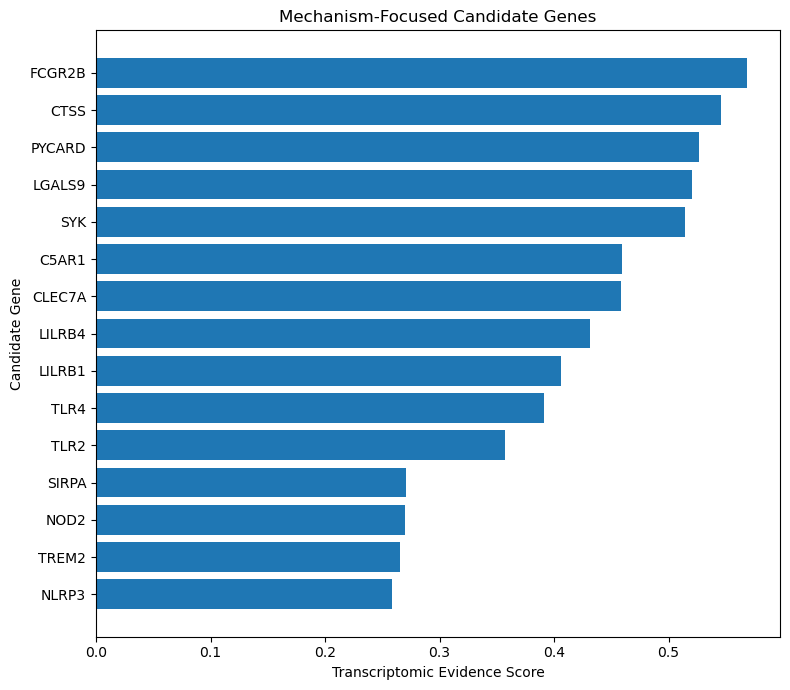

In [32]:
plot_targets = (
    mechanism_targets
    .head(15)
    .sort_values(
        "Transcriptomic_Evidence_Score",
        ascending=True
    )
)

plt.figure(figsize=(8, 7))

plt.barh(
    plot_targets["Gene"],
    plot_targets["Transcriptomic_Evidence_Score"]
)

plt.xlabel("Transcriptomic Evidence Score")
plt.ylabel("Candidate Gene")
plt.title("Mechanism-Focused Candidate Genes")

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "05_mechanism_focused_candidates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

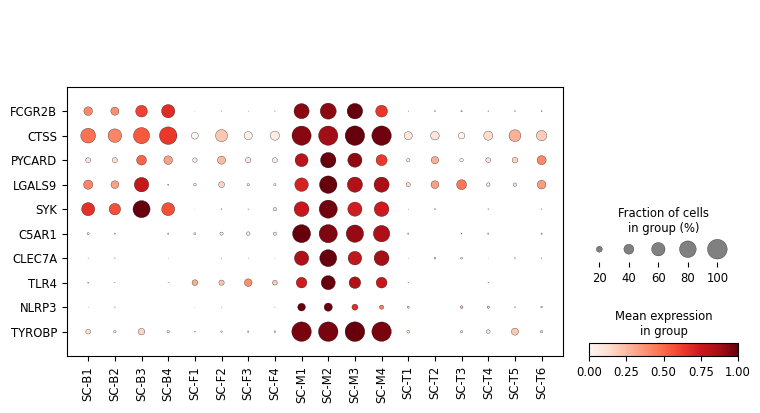

In [33]:
dotplot_genes = [
    "FCGR2B",
    "CTSS",
    "PYCARD",
    "LGALS9",
    "SYK",
    "C5AR1",
    "CLEC7A",
    "TLR4",
    "NLRP3",
    "TYROBP"
]

dotplot_genes = [
    gene
    for gene in dotplot_genes
    if gene in adata.var_names
]

sc.pl.dotplot(
    adata,
    var_names=dotplot_genes,
    groupby="Cluster",
    standard_scale="var",
    swap_axes=True,
    show=False
)

plt.savefig(
    FIGURES_DIR / "06_candidate_expression_dotplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 15. Sample-Level Robustness

Single cells originating from the same sample are not independent biological replicates. Therefore, additional analyses were performed at the sample level to assess whether major cell-state structures and candidate-gene signals were dominated by individual sequencing samples.

Three complementary checks were performed:

1. cell-state composition across samples,
2. sample mixing within the UMAP embedding, and
3. candidate-gene expression across samples within SC-M1.

In [34]:
sample_cluster_counts = pd.crosstab(
    adata.obs["Sample"],
    adata.obs["Cluster"]
)

sample_cluster_props = sample_cluster_counts.div(
    sample_cluster_counts.sum(axis=1),
    axis=0
)

display(sample_cluster_props.head())

Cluster,SC-B1,SC-B2,SC-B3,SC-B4,SC-F1,SC-F2,SC-F3,SC-F4,SC-M1,SC-M2,SC-M3,SC-M4,SC-T1,SC-T2,SC-T3,SC-T4,SC-T5,SC-T6
Sample,,,,,,,,,,,,,,,,,,
S006,0.000000,0.000000,0.000000,0.000000,0.034722,0.055556,0.003472,0.211806,0.076389,0.211806,0.003472,0.000000,0.218750,0.006944,0.006944,0.152778,0.003472,0.013889
S010,0.000000,0.000000,0.000000,0.000000,0.102041,0.040816,0.089796,0.089796,0.057143,0.248980,0.000000,0.000000,0.093878,0.004082,0.008163,0.253061,0.000000,0.012245
S012,0.004049,0.032389,0.000000,0.109312,0.344130,0.036437,0.085020,0.028340,0.000000,0.000000,0.000000,0.000000,0.186235,0.004049,0.004049,0.109312,0.048583,0.008097
S013,0.036145,0.192771,0.060241,0.126506,0.000000,0.000000,0.000000,0.000000,0.018072,0.006024,0.048193,0.012048,0.066265,0.000000,0.030120,0.397590,0.000000,0.006024
S014,0.072650,0.089744,0.004274,0.200855,0.072650,0.282051,0.017094,0.068376,0.012821,0.000000,0.012821,0.004274,0.034188,0.012821,0.034188,0.076923,0.000000,0.004274


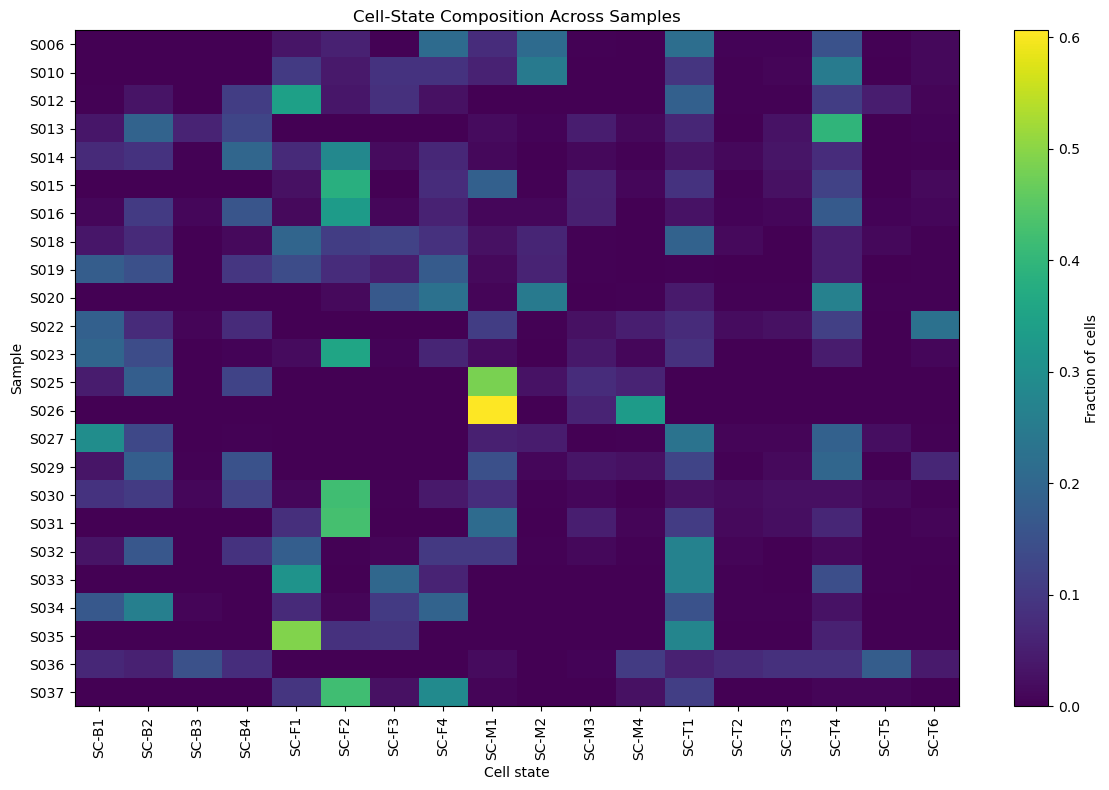

In [35]:
fig, ax = plt.subplots(figsize=(12, 8))

image = ax.imshow(
    sample_cluster_props.values,
    aspect="auto"
)

ax.set_xticks(
    range(len(sample_cluster_props.columns))
)

ax.set_xticklabels(
    sample_cluster_props.columns,
    rotation=90
)

ax.set_yticks(
    range(len(sample_cluster_props.index))
)

ax.set_yticklabels(
    sample_cluster_props.index
)

ax.set_xlabel("Cell state")
ax.set_ylabel("Sample")
ax.set_title("Cell-State Composition Across Samples")

fig.colorbar(
    image,
    ax=ax,
    label="Fraction of cells"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "07_sample_cell_state_composition.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

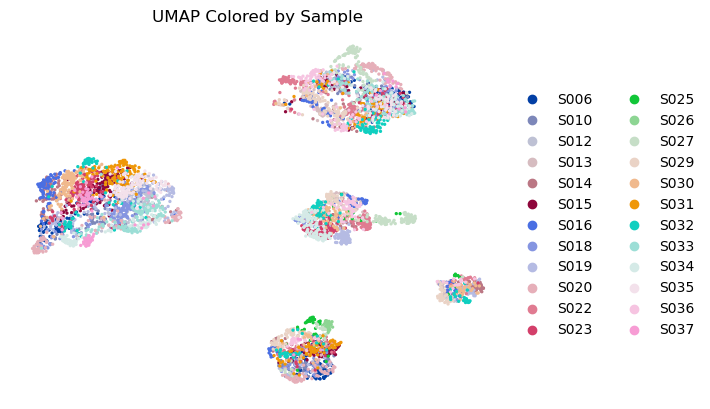

In [36]:
sc.pl.umap(
    adata,
    color="Sample",
    title="UMAP Colored by Sample",
    frameon=False,
    legend_loc="right margin",
    show=False
)

plt.savefig(
    FIGURES_DIR / "08_umap_by_sample.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:
sample_candidate_genes = [
    "PYCARD",
    "SYK",
    "CTSS",
    "FCGR2B",
    "CLEC7A",
    "C5AR1",
    "TYROBP",
    "NLRP3"
]

sample_expression_rows = []

for sample in adata.obs["Sample"].unique():

    mask = (
        (adata.obs["Sample"] == sample) &
        (adata.obs["Cluster"] == "SC-M1")
    )

    n_cells = int(mask.sum())

    # Require at least 10 SC-M1 cells for a sample-level estimate
    if n_cells < 10:
        continue

    X = np.asarray(
        adata[
            mask,
            sample_candidate_genes
        ].X
    )

    mean_expression = X.mean(axis=0)
    pct_expressed = (X > 0).mean(axis=0)

    for gene, mean_expr, pct in zip(
        sample_candidate_genes,
        mean_expression,
        pct_expressed
    ):
        sample_expression_rows.append({
            "Sample": sample,
            "Cluster": "SC-M1",
            "Gene": gene,
            "N_cells": n_cells,
            "MeanExpression": mean_expr,
            "PctExpressed": pct
        })

sample_candidate_expression = pd.DataFrame(
    sample_expression_rows
)

print(
    "Samples with >=10 SC-M1 cells:",
    sample_candidate_expression["Sample"].nunique()
)

display(sample_candidate_expression.head())

Samples with >=10 SC-M1 cells: 11


,Sample,Cluster,Gene,N_cells,MeanExpression,PctExpressed
0,S006,SC-M1,PYCARD,22,4.793743,0.590909
1,S006,SC-M1,SYK,22,7.289503,0.863636
2,S006,SC-M1,CTSS,22,8.043891,0.863636
3,S006,SC-M1,FCGR2B,22,6.478188,0.727273
4,S006,SC-M1,CLEC7A,22,5.794589,0.681818


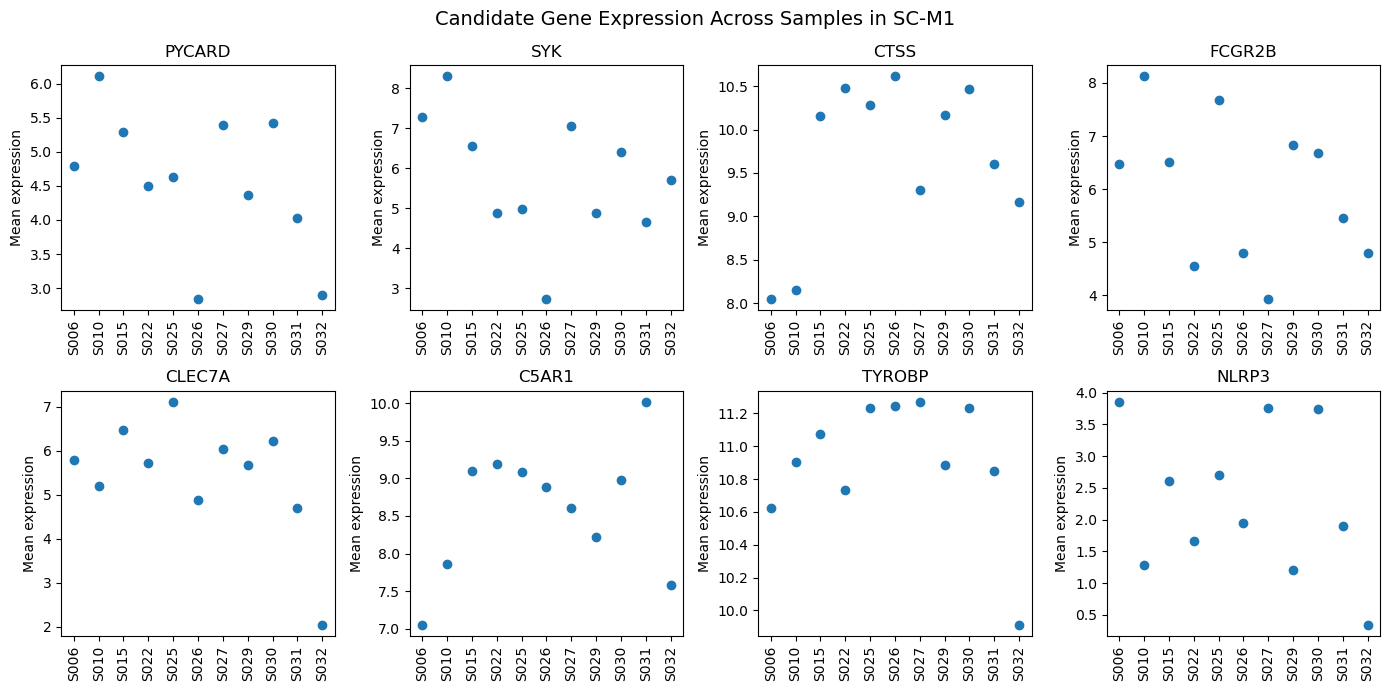

In [ ]:
samples = sorted(
    sample_candidate_expression["Sample"].unique()
)

fig, axes = plt.subplots(
    2,
    4,
    figsize=(14, 7)
)

axes = axes.flatten()

for gene, ax in zip(
    sample_candidate_genes,
    axes
):

    temp = (
        sample_candidate_expression[
            sample_candidate_expression["Gene"] == gene
        ]
        .set_index("Sample")
        .reindex(samples)
        .reset_index()
    )

    ax.scatter(
        temp["Sample"],
        temp["MeanExpression"]
    )

    ax.set_title(gene)
    ax.set_ylabel("Mean expression")
    ax.tick_params(
        axis="x",
        rotation=90
    )

plt.suptitle(
    "Candidate Gene Expression Across Samples in SC-M1",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "08_scm1_candidate_sample_reproducibility.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 16. Export Results

Key intermediate and final analysis outputs are exported as CSV files to support reproducibility and allow results to be inspected without rerunning the full notebook.

In [39]:
# Export differential-expression results
markers.to_csv(
    RESULTS_DIR / "cluster_markers.csv",
    index=False
)

# Export significant ranked-GSEA pathways
gsea_summary.to_csv(
    RESULTS_DIR / "significant_gsea_pathways.csv",
    index=False
)

# Export cell-state-level candidate genes
candidate_table.to_csv(
    RESULTS_DIR / "cell_state_candidate_genes.csv",
    index=False
)

# Export gene-level integrated candidate evidence
target_table.to_csv(
    RESULTS_DIR / "gene_level_target_prioritization.csv",
    index=False
)

# Export mechanism-focused candidate shortlist
mechanism_targets.to_csv(
    RESULTS_DIR / "mechanism_focused_candidate_targets.csv",
    index=False
)

# Export ranking robustness analysis
robustness_summary.to_csv(
    RESULTS_DIR / "target_ranking_robustness.csv",
    index=False
)

# Export sample-level candidate expression
sample_candidate_expression.to_csv(
    RESULTS_DIR / "sample_candidate_expression.csv",
    index=False
)

print("Results exported successfully.")

Results exported successfully.


In [40]:
result_files = sorted(
    RESULTS_DIR.glob("*.csv")
)

print("Exported result files:")

for file in result_files:
    print("-", file.name)

Exported result files:
- cell_state_candidate_genes.csv
- cluster_markers.csv
- external_validation_summary.csv
- gene_level_target_prioritization.csv
- gsea_significant_pathways.csv
- mechanism_focused_candidate_targets.csv
- sample_candidate_expression.csv
- significant_gsea_pathways.csv
- target_ranking_robustness.csv
- top_candidates_by_cell_state.csv


In [ ]:
print("RA SINGLE-CELL TARGET PRIORITIZATION — ANALYSIS SUMMARY")

print(f"Cells analyzed: {adata.n_obs:,}")
print(f"Genes analyzed: {adata.n_vars:,}")
print(f"Published cell states: {adata.obs['Cluster'].nunique()}")
print(f"Sequencing samples: {adata.obs['Sample'].nunique()}")
print(f"Highly variable genes: {int(adata.var['highly_variable'].sum()):,}")
print(f"Significant positive GSEA pathways: {len(gsea_summary):,}")
print(f"Candidate cluster-gene pairs: {len(candidate_table):,}")
print(f"Unique candidate genes: {len(gene_summary):,}")
print(f"Stable genes across weighting schemes: {len(stable_targets)}")
print(f"Stable genes after leave one feature out: {len(stable_leave_one_out)}")

RA SINGLE-CELL TARGET PRIORITIZATION — ANALYSIS SUMMARY
Cells analyzed: 5,265
Genes analyzed: 29,165
Published cell states: 18
Sequencing samples: 24
Highly variable genes: 2,000
Significant positive GSEA pathways: 132
Candidate cluster-gene pairs: 1,018
Unique candidate genes: 673
Stable genes across weighting schemes: 8
Stable genes after leave one feature out: 4


## 17. Results Summary and Limitations

### Key Results

This analysis reanalyzed **5,265 synovial single-cell transcriptomes across 18 published cell states** and identified distinct transcriptional programs across fibroblast, monocyte, T-cell, and B-cell populations.

Ranked GSEA identified **132 significantly positively enriched biological processes (FDR < 0.05)** across five disease-relevant cell states. Prominent programs included:

- inflammatory, chemokine, IL-6, and IL-1β signaling in **SC-M1 pro-inflammatory monocytes**
- immune activation, phagocytosis, and interferon-associated programs in **SC-M4 monocytes**
- B-cell activation and differentiation in **SC-B3 autoimmune-associated B cells**
- extracellular-matrix and collagen organization in **SC-F2 fibroblasts**

Leading-edge analysis identified **1,018 cell-state–gene candidate pairs representing 673 unique genes**. Integration of pathway recurrence, cross-cell-state recurrence, expression effect size, differential-expression strength, and statistical evidence produced an exploratory Transcriptomic Evidence Score.

The strongest unbiased computational signal converged on **MHC class II antigen presentation and myeloid immune biology**, with HLA-DPA1, HLA-DRA, HLA-DRB1, and TYROBP remaining among the top 20 candidates after removal of any single scoring feature.

A complementary mechanism-focused analysis highlighted immune-signaling candidates including **FCGR2B, CTSS, PYCARD, LGALS9, SYK, C5AR1, CLEC7A, TLR4, and NLRP3** for downstream therapeutic investigation.

### Robustness

Candidate prioritization was evaluated using alternative weighting schemes and leave-one-feature-out sensitivity analysis.

Eight genes remained among the top 20 across all tested weighting schemes:

**CTSS, FCER1G, HLA-DPA1, HLA-DQA1, HLA-DRA, HLA-DRB1, IFI30, and TYROBP.**

Four genes remained among the top 20 regardless of which individual evidence component was removed:

**HLA-DPA1, HLA-DRA, HLA-DRB1, and TYROBP.**

UMAP visualization by sample showed that major transcriptional compartments contained cells from multiple sequencing samples rather than being visually dominated by a single sample. Sample-level analysis of SC-M1 further showed that several candidate-gene signals were observed across multiple samples, although substantial inter-sample heterogeneity remained.

### Interpretation

The results support a model in which RA synovial cell states contain distinct but overlapping antigen-presentation, inflammatory, innate-immune, and extracellular-matrix programs.

The candidate rankings should be interpreted as **prioritized transcriptomic hypotheses rather than validated therapeutic targets**. High transcriptomic evidence indicates consistent involvement in disease-relevant cellular programs but does not establish druggability, safety, causal disease involvement, or clinical efficacy.

### Limitations

- The expression matrix was already quality controlled and transformed to `log2(CPM + 1)` by the original study; therefore, this project is a reanalysis of processed data rather than a raw sequencing workflow.
- Published cell-state annotations were used rather than generating de novo biological annotations.
- Individual cells are not independent biological replicates. Sample-level analyses were therefore included as robustness checks.
- A complete sample-to-patient clinical crosswalk was not available in the analyzed files, preventing direct patient-level RA-versus-OA differential analysis.
- Ranked GSEA contained tied Wilcoxon statistics, predominantly among genes with weak differential-expression evidence. No artificial jitter was introduced to modify the original ranking statistic.
- The Transcriptomic Evidence Score is an exploratory composite score. Sensitivity analyses were used to evaluate dependence on feature weighting, but the score has not been prospectively validated.
- Mechanism-focused candidates require external genetic, pharmacologic, safety, druggability, and clinical validation before therapeutic conclusions can be made.